In [4]:
%pip install torch torchtext datasets scikit-learn pandas matplotlib seaborn

  Using cached datasets-5.0.1-py3-none-any.whl.metadata (23 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.6.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/124.1 MB ? eta -:--:--
   ---------------------------------------- 1.0/124.1 MB 3.0 MB/s eta 0:00:42
    --------------------------------------- 1.8/124.1 MB 3.1 MB/s eta 0:00:39
    --------------------------------------- 2.4/124.1 MB 3.1 MB/s eta 0:00:40
    --------------------------------------- 2.9/124.1 MB 3.1 MB/s eta 0:00:40
   - -------------------------------------- 3.7/124.1 MB 3.1 MB/s eta 0:00:39
   - -------------------------------------- 4.5/124.1 MB 3.1 MB/s eta 0:00:39
   - -------------------------------------- 5.0/124.1 MB 3.1 M

In [5]:
# pip install torch torchtext datasets scikit-learn pandas matplotlib seaborn
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from datasets import load_dataset
from collections import Counter
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import string

c:\Users\kiro1\anaconda3\envs\ml_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Matplotlib is building the font cache; this may take a moment.


In [12]:

dataset = load_dataset('mteb/banking77')
train_raw, test_raw = dataset['train'], dataset['test']

# 2. Map fine-grained intents to our 4 e-commerce intents
def map_intents(label_name):
    # We now pass the string label directly, bypassing int2str
    mapping = {
        "card_arrival": 1, "card_delivery_estimate": 1, "order_physical_card": 1, 
        "Refund_not_showing_up": 2, "request_refund": 2, "reverted_card_payment?": 2, 
        "card_payment_fee_charged": 0, "declined_card_payment": 0, "transaction_charged_twice": 0,
    }
    # Anything not in mapping falls back to 'general' (index 3)
    return mapping.get(label_name, 3)

# Note: Load and append your Groq-generated synthetic CSV data to train_texts/train_labels here

# Change item['label'] to item['label_text'] here:
train_texts = [item['text'] for item in train_raw]
train_labels = [map_intents(item['label_text']) for item in train_raw]
test_texts = [item['text'] for item in test_raw]
test_labels = [map_intents(item['label_text']) for item in test_raw]

# 3. Tokenization & Vocabulary setup
def tokenize(text):
    # Lowercase, strip punctuation, tokenize on whitespace[cite: 4]
    text = text.lower().translate(str.maketrans('', '', string.punctuation))
    return text.split() 

all_tokens = [word for text in train_texts for word in tokenize(text)]
vocab_counter = Counter(all_tokens)

# Cap at 15,000 most frequent tokens[cite: 4]
vocab = {"<pad>": 0, "<unk>": 1} #[cite: 4]
for idx, (word, _) in enumerate(vocab_counter.most_common(15000), start=2):
    vocab[word] = idx

def text_to_indices(text):
    return [vocab.get(token, vocab["<unk>"]) for token in tokenize(text)]

In [13]:
MAX_LEN = 40 #[cite: 4]

class IntentDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels
        
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        indices = text_to_indices(self.texts[idx])
        # Truncate
        if len(indices) > MAX_LEN:
            indices = indices[:MAX_LEN]
        length = len(indices) if len(indices) > 0 else 1 # Avoid 0 length
        return torch.tensor(indices), torch.tensor(self.labels[idx]), length

def collate_fn(batch):
    sequences, labels, lengths = zip(*batch)
    # Pad sequences to max length with <pad> token at index 0[cite: 4, 5]
    padded_seqs = pad_sequence(sequences, batch_first=True, padding_value=0)
    return padded_seqs, torch.tensor(labels), torch.tensor(lengths)

train_dataset = IntentDataset(train_texts, train_labels)
test_dataset = IntentDataset(test_texts, test_labels)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=collate_fn)

In [14]:
class IntentClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=100, hidden_dim=128, num_classes=4, n_layers=1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0) #
        
        # Swappable to nn.GRU
        self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers=n_layers, 
                           batch_first=True, bidirectional=True) #
        
        self.dropout = nn.Dropout(0.3) #
        self.fc = nn.Linear(hidden_dim * 2, num_classes) #

    def forward(self, x, lengths):
        embedded = self.embedding(x)
        
        # Pack padded sequence[cite: 5]
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.rnn(packed) #[cite: 5]
        
        # Concat final forward and backward hidden states[cite: 5]
        h = torch.cat((hidden[-2], hidden[-1]), dim=1) #[cite: 5]
        return self.fc(self.dropout(h)) #[cite: 5]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = IntentClassifier(vocab_size=len(vocab)).to(device)

In [15]:
criterion = nn.CrossEntropyLoss() #[cite: 5]
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3) #[cite: 5]
epochs = 10 #[cite: 5]

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for batch_seqs, batch_labels, batch_lengths in train_loader:
        batch_seqs, batch_labels = batch_seqs.to(device), batch_labels.to(device)
        
        optimizer.zero_grad()
        predictions = model(batch_seqs, batch_lengths)
        loss = criterion(predictions, batch_labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss/len(train_loader):.4f}")

Epoch 1/10 | Loss: 0.4657
Epoch 2/10 | Loss: 0.1775
Epoch 3/10 | Loss: 0.0940
Epoch 4/10 | Loss: 0.0613
Epoch 5/10 | Loss: 0.0355
Epoch 6/10 | Loss: 0.0255
Epoch 7/10 | Loss: 0.0187
Epoch 8/10 | Loss: 0.0114
Epoch 9/10 | Loss: 0.0083
Epoch 10/10 | Loss: 0.0114


Classification Report:
                 precision    recall  f1-score   support

        billing       0.86      0.83      0.85       120
   order_status       0.93      0.84      0.88       120
returns_refunds       0.87      0.93      0.90       120
        general       0.98      0.99      0.99      2716

       accuracy                           0.97      3076
      macro avg       0.91      0.90      0.90      3076
   weighted avg       0.97      0.97      0.97      3076



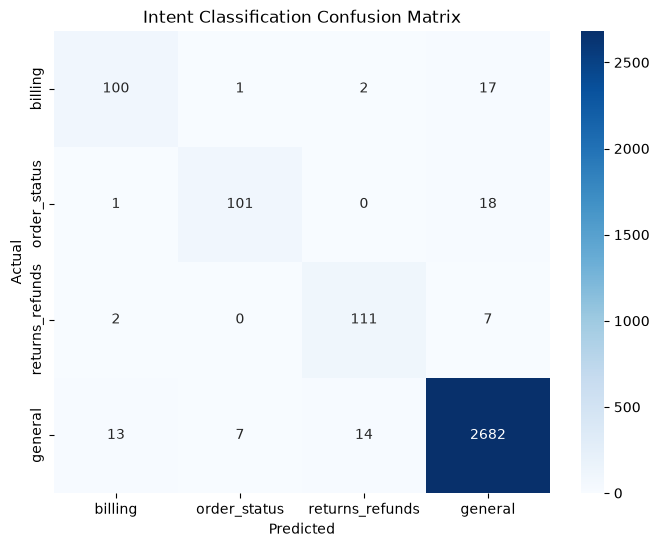

In [16]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for batch_seqs, batch_labels, batch_lengths in test_loader:
        batch_seqs = batch_seqs.to(device)
        outputs = model(batch_seqs, batch_lengths)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(batch_labels.numpy())

target_names = ['billing', 'order_status', 'returns_refunds', 'general']

# 1. Macro-F1 & Accuracy[cite: 5]
print("Classification Report:")
print(classification_report(all_targets, all_preds, target_names=target_names))

# 2. Confusion Matrix[cite: 5]
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=target_names, yticklabels=target_names, cmap='Blues')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Intent Classification Confusion Matrix')
plt.show()

# (Remember to add your one-sentence explanation per off-diagonal cell in your write-up!)[cite: 5]

In [17]:
torch.save({
    'model_state': model.state_dict(),
    'vocab': vocab,
    'label_map': {0: 'billing', 1: 'order_status', 2: 'returns_refunds', 3: 'general'}
}, 'classifier.pt') #[cite: 5]
print("Model saved successfully as classifier.pt")

Model saved successfully as classifier.pt
